# Analiza czynników rezygnacji ze studiów

Jeden notatnik na cały projekt. Tu jest diagnostyka braków i jakości danych: co jest luką, co jest zerem na skali, co jest błędem zapisu, a czego nie ruszamy.

Surowy plik Excela nie jest nadpisywany. Wyniki są w komórkach poniżej, nie w osobnych skryptach.


## 1. Pytania i zbiór

Pytanie na później, w tym samym pliku: które cechy studenta i przebiegu studiów wiążą się z rezygnacją.

Pytanie na teraz: czy puste pola i zera są brakami do imputacji, czy informacją, której nie wolno wyciąć.

Zbiór to losowa próba 800 rekordów z UCI *Predict Students Dropout and Academic Success* (oryginał ma 4424 wiersze, Portugalia). Kategorie są już po polsku. Jednostka obserwacji to student. Jedna tabela, bez łączenia zbiorów i bez `melt`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer

%matplotlib inline

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")

STATUS_ORDER = ["Ukończył", "Nadal studiuje", "Zrezygnował"]
STATUS_COLORS = {
    "Ukończył": "#4c78a8",
    "Nadal studiuje": "#72b7b2",
    "Zrezygnował": "#e45756",
}
SENTINEL_TEXT = {
    "", "nan", "none", "null", "brak", "brak danych", "bd", "nd",
    "n/a", "na", "-", "--", "?", ".", "nieznane", "nieznany", "nieznana",
}


def find_data():
    names = ("Dane_studenci.xlsx", "Dane_studentci.xlsx")
    here = Path.cwd().resolve()
    for start in [here, *here.parents]:
        for name in names:
            for candidate in (
                start / "data" / "raw" / name,
                start / "Projekt" / "data" / "raw" / name,
            ):
                if candidate.is_file():
                    return candidate
    raise FileNotFoundError("Nie widzę pliku w data/raw.")


def pick(frame, parts, excluded=()):
    hits = [
        name for name in frame.columns
        if all(part in str(name) for part in parts)
        and not any(part in str(name) for part in excluded)
    ]
    if len(hits) != 1:
        raise KeyError(f"Szukam {parts}, wykluczam {excluded}, trafienia: {hits}")
    return hits[0]


def percent(n, total):
    if total == 0:
        return "0%"
    return f"{100 * n / total:.1f}%"


def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


## 2. Co jest w pliku

Najpierw arkusz z opisem, potem tabela studentów. Nazwy kolumn biorę po fragmencie tekstu, żeby myślnik w nagłówku nie rozjechał kodu.


In [2]:
path = find_data()
df = pd.read_excel(path, sheet_name=0)
opis = pd.read_excel(path, sheet_name=1, header=None)

c_status = pick(df, ("Status",))
c_mom = pick(df, ("Wykształcenie matki",))
c_rec = pick(df, ("Tryb rekrutacji",))
c_prog = pick(df, ("Kierunek",))
c_mode = pick(df, ("Tryb studiów",))
c_pref = pick(df, ("Preferencja",))
c_prev = pick(df, ("poprzedniego",))
c_adm = pick(df, ("przyjęciu",))
c_age = pick(df, ("Wiek",))
c_enr = pick(df, ("Semestr 1", "zapisanych"))
c_ap1 = pick(df, ("Semestr 1", "zaliczonych"))
c_g1 = pick(df, ("Semestr 1", "średnia"))
c_ap2 = pick(df, ("Semestr 2", "zaliczonych"))
c_g2 = pick(df, ("Semestr 2", "średnia"))
c_unemp = pick(df, ("bezrobocia",))
c_sex = pick(df, ("Płeć",))
c_debt = pick(df, ("Zadłużenie",))
c_fees = pick(df, ("Opłaty",))
c_disp = pick(df, ("przesiedlona",))
c_schol = pick(df, ("Stypendysta",))
c_marital = pick(df, ("Stan cywilny",))

n = len(df)
print(f"Plik: {path.name}")
print(f"Wierszy: {n}. Kolumn: {df.shape[1]}.")
opis.dropna(how="all")


Plik: Dane_studentci.xlsx
Wierszy: 800. Kolumn: 21.


,0,1
0,INFORMACJE O ZBIORZE,NaN
1,Nazwa,Analiza czynników rezygnacji ze studiów
2,Liczba obserwacji,800
3,Liczba zmiennych,21
4,Źródło,UCI Machine Learning Repository – Predict Stud...
5,Zakres,Portugalia; losowa próba 800 z oryginalnych 44...
6,Przekształcenia,Kategorie liczbowe zamienione na polskie nazwy...
7,Zachowane wartości,"Wiek, oceny, liczba przedmiotów, kolejność pre..."
8,Uwagi,"Kolejność preferencji kierunku jest rangą 0–9,..."
9,Wyniki ocen,Portugalska skala ocen 0–20 dla wyników semest...


In [3]:
df.head()


,Stan cywilny,Tryb rekrutacji,Preferencja kierunku przy rekrutacji,Kierunek studiów,Tryb studiów (dzienny/wieczorowy),Wynik poprzedniego etapu edukacji,Wykształcenie matki,Wynik przy przyjęciu na studia,Osoba przesiedlona / spoza miejsca zamieszkania,Zadłużenie,Opłaty za studia uregulowane,Płeć,Stypendysta,Wiek w chwili rozpoczęcia studiów,Semestr 1 – liczba zapisanych przedmiotów,Semestr 1 – liczba zaliczonych przedmiotów,Semestr 1 – średnia ocen,Semestr 2 – liczba zaliczonych przedmiotów,Semestr 2 – średnia ocen,Stopa bezrobocia (%),Status studenta
0,Wolny/a,II tura – nabór ogólny,1,Zarządzanie,Dzienne,140.000,Wykształcenie podstawowe – I etap,132.300,Tak,Nie,Tak,Kobieta,Nie,20,5,1,10.000,1,11.000,7.600,Zrezygnował
1,Wolny/a,II tura – nabór ogólny,2,Praca socjalna,Dzienne,125.000,Wykształcenie podstawowe – III etap,118.000,Tak,Nie,Tak,Kobieta,Nie,18,6,5,11.000,4,11.250,8.900,Ukończył
2,Wolny/a,I tura – nabór ogólny,1,Pielęgniarstwo weterynaryjne,Dzienne,101.000,Wykształcenie podstawowe – I etap,101.000,Tak,Tak,Tak,Kobieta,Nie,22,6,5,13.333,4,11.400,12.400,Nadal studiuje
3,Wolny/a,I tura – nabór ogólny,1,Dziennikarstwo i komunikacja,Dzienne,150.000,Wykształcenie podstawowe – III etap,131.100,Tak,Nie,Tak,Mężczyzna,Nie,19,6,6,11.667,3,12.667,7.600,Ukończył
4,Rozwiedziony/a,Kandydat powyżej 23 lat,1,Zarządzanie (wieczorowe),Wieczorowe,147.000,Wykształcenie podstawowe – III etap,147.900,Nie,Nie,Tak,Kobieta,Nie,28,5,4,11.500,4,12.000,10.800,Nadal studiuje


In [4]:
df[c_status].value_counts().reindex(STATUS_ORDER).to_frame("n")


,n
Status studenta,
Ukończył,399
Nadal studiuje,144
Zrezygnował,257


Status jest zmienną, którą później będziemy opisywać. Udział rezygnacji liczę niżej, przy braku, żeby od razu było widać, czy wycięcie wierszy zmienia ten udział.


## 3. Identyfikacja braków

Z zajęć: `isna`, `info`, `duplicated`. Potem kody słowne. W ankiecie i w rejestrze brak często nie jest `NaN`, tylko etykietą albo zerem.


In [5]:
print("Suma isna:", int(df.isna().sum().sum()))
print("Suma isnull, to samo:", int(df.isnull().sum().sum()))
print("Pełne duplikaty wierszy:", int(df.duplicated().sum()))

info = pd.DataFrame({
    "typ": df.dtypes.astype(str),
    "niepuste": df.notna().sum(),
    "isna": df.isna().sum(),
    "unikalne": df.nunique(dropna=True),
})
info


Suma isna: 0
Suma isnull, to samo: 0
Pełne duplikaty wierszy: 0


,typ,niepuste,isna,unikalne
Stan cywilny,object,800,0,4
Tryb rekrutacji,object,800,0,14
Preferencja kierunku przy rekrutacji,int64,800,0,7
Kierunek studiów,object,800,0,17
Tryb studiów (dzienny/wieczorowy),object,800,0,2
Wynik poprzedniego etapu edukacji,float64,800,0,70
Wykształcenie matki,object,800,0,17
Wynik przy przyjęciu na studia,float64,800,0,366
Osoba przesiedlona / spoza miejsca zamieszkania,object,800,0,2
Zadłużenie,object,800,0,2


In [6]:
sentinel_rows = []
for col in df.select_dtypes(include="object").columns:
    cleaned = df[col].astype(str).str.strip().str.lower()
    mask = cleaned.isin(SENTINEL_TEXT)
    if mask.any():
        counts = df.loc[mask, col].astype(str).value_counts()
        sentinel_rows.append({
            "kolumna": col,
            "n": int(mask.sum()),
            "udzial": percent(int(mask.sum()), n),
            "wartosci": ", ".join(f"{label} ({count})" for label, count in counts.items()),
        })

if sentinel_rows:
    display(pd.DataFrame(sentinel_rows))
else:
    print("Kodów słownych typu brak, nd, pusty string nie ma.")

edges = 0
for col in df.select_dtypes(include="object").columns:
    text = df[col].dropna().astype(str)
    edges += int((text != text.str.strip()).sum())
print("Etykiet z białą spacją na brzegu:", edges)


,kolumna,n,udzial,wartosci
0,Wykształcenie matki,26,3.2%,Nieznane (26)


Etykiet z białą spacją na brzegu: 0


Pandasa `NaN` nie ma w żadnej kolumnie. Duplikatów też nie. Jedyny kod, który traktuję jak brak, a nie jak poziom cechy, to `Nieznane` przy wykształceniu matki: 26 wierszy, 3,2%.

Reszty etykiet nie ruszam. `Tak`/`Nie` i `Kobieta`/`Mężczyzna` są zapisane spójnie, bez spacji na brzegach.


## 4. Wzorzec braku

Zamiana jest na kopii. Surowa kolumna zostaje z etykietą `Nieznane`, bo tej decyzji jeszcze nie ma.

Krok z zajęć: czy Y wygląda inaczej, gdy X jest puste. Tu Y to status, wiek, wynik przyjęcia i średnia z pierwszego semestru.


In [7]:
work = df.copy()
work[c_mom] = work[c_mom].replace({"Nieznane": np.nan})
known = work[c_mom].notna()
unknown = work[c_mom].isna()
dropout = df[c_status].eq("Zrezygnował")

print(f"Braki po zamianie Nieznane -> NA: {int(work.isna().sum().sum())}, kolumny: {work.isna().sum().loc[lambda s: s > 0].to_dict()}")
print(f"Rezygnacje, znane wykształcenie: {int(dropout[known].sum())}/{int(known.sum())} ({percent(int(dropout[known].sum()), int(known.sum()))})")
print(f"Rezygnacje, Nieznane: {int(dropout[unknown].sum())}/{int(unknown.sum())} ({percent(int(dropout[unknown].sum()), int(unknown.sum()))})")
print(f"Rezygnacje, cały plik: {int(dropout.sum())}/{n} ({percent(int(dropout.sum()), n)})")

tab_status = pd.crosstab(
    df[c_status],
    unknown.map({False: "znane", True: "Nieznane"}),
    margins=True,
)
chi2, p_chi, dof, _ = stats.chi2_contingency(tab_status.iloc[:-1, :-1])
print(f"Chi-kwadrat status x brak: chi2={chi2:.2f}, df={dof}, p={p_chi:.4g}")
tab_status


Braki po zamianie Nieznane -> NA: 26, kolumny: {'Wykształcenie matki': 26}


Rezygnacje, znane wykształcenie: 238/774 (30.7%)
Rezygnacje, Nieznane: 19/26 (73.1%)
Rezygnacje, cały plik: 257/800 (32.1%)
Chi-kwadrat status x brak: chi2=21.70, df=2, p=1.936e-05


Wykształcenie matki,Nieznane,znane,All
Status studenta,,,
Nadal studiuje,0,144,144
Ukończył,7,392,399
Zrezygnował,19,238,257
All,26,774,800


In [8]:
pd.DataFrame({
    "znane": [
        df.loc[known, c_age].mean(),
        df.loc[known, c_adm].mean(),
        df.loc[known, c_g1].mean(),
    ],
    "Nieznane": [
        df.loc[unknown, c_age].mean(),
        df.loc[unknown, c_adm].mean(),
        df.loc[unknown, c_g1].mean(),
    ],
}, index=["wiek", "wynik przyjęcia", "średnia s1"])


,znane,Nieznane
wiek,23.079,29.269
wynik przyjęcia,127.220,116.227
średnia s1,10.528,8.207


C:\Users\biesi\AppData\Local\Temp\ipykernel_22236\157526575.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


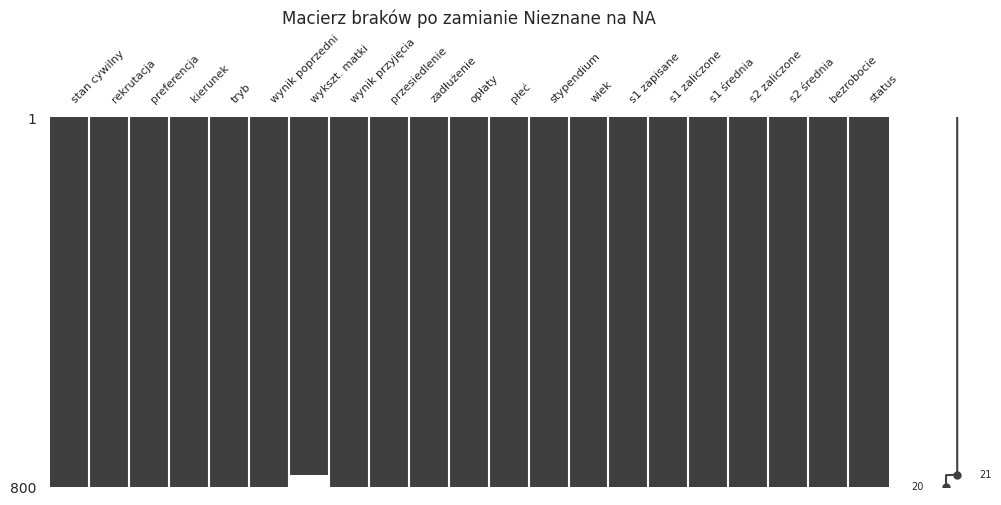

In [9]:
short = {
    c_marital: "stan cywilny",
    c_rec: "rekrutacja",
    c_pref: "preferencja",
    c_prog: "kierunek",
    c_mode: "tryb",
    c_prev: "wynik poprzedni",
    c_mom: "wykszt. matki",
    c_adm: "wynik przyjęcia",
    c_disp: "przesiedlenie",
    c_debt: "zadłużenie",
    c_fees: "opłaty",
    c_sex: "płeć",
    c_schol: "stypendium",
    c_age: "wiek",
    c_enr: "s1 zapisane",
    c_ap1: "s1 zaliczone",
    c_g1: "s1 średnia",
    c_ap2: "s2 zaliczone",
    c_g2: "s2 średnia",
    c_unemp: "bezrobocie",
    c_status: "status",
}
msno.matrix(work.rename(columns=short), figsize=(12, 4.8), fontsize=8, sort="descending", sparkline=True)
plt.title("Macierz braków po zamianie Nieznane na NA")
plt.tight_layout()
plt.show()


Jasne kreski są tylko przy wykształceniu matki. Reszta macierzy jest pełna. To jest wynik, nie pusty wykres do poprawienia.

`msno.heatmap` pomijam. Przy jednej kolumnie z brakiem korelacja braków nie ma z czego powstać. Na zajęciach niska korelacja braków była argumentem za MAR, ale tu nie ma drugiej luki, z którą dałoby się ją policzyć.

Chi-kwadrat sprawdza tylko, czy rozkład statusu jest taki sam. Nie rozstrzyga MAR i MNAR.

Brak nie wygląda na MCAR. Przy `Nieznane` rezygnacji jest 73,1%, w całym pliku 32,1%, a wśród nadal studiujących tego kodu nie ma wcale. Te osoby są też starsze (29,3 vs 23,1 roku) i mają słabszy wynik przyjęcia oraz słabszą średnią z pierwszego semestru.

MAR jest możliwe, jeśli kompletność rekordu zależy od przebiegu studiów, który znamy. MNAR też jest możliwe, jeśli samo wykształcenie matki, którego nie widzimy, wiąże się z pustym polem. Z tego pliku tego nie rozdzielę. Dlatego `Nieznane` zostaje osobnym poziomem. Tych 26 wierszy nie wycinam z analizy rezygnacji.


## 5. Zera to nie braki

Opis pliku podaje portugalską skalę 0–20. Zero może być brakiem zaliczenia, a nie pustą komórką. Sprawdzam, czy zero oceny chodzi w parze z zerem zaliczeń.


In [10]:
g1_zero = df[c_g1].eq(0)
g2_zero = df[c_g2].eq(0)
ap1_zero = df[c_ap1].eq(0)
ap2_zero = df[c_ap2].eq(0)
enr_zero = df[c_enr].eq(0)

zero_check = pd.DataFrame({
    "n": [
        int(g1_zero.sum()),
        int(ap1_zero.sum()),
        int(g2_zero.sum()),
        int(ap2_zero.sum()),
        int(enr_zero.sum()),
        int((g1_zero == ap1_zero).sum()),
        int((g2_zero == ap2_zero).sum()),
        int((enr_zero & ap1_zero & g1_zero).sum()),
        int((g1_zero & g2_zero).sum()),
        int((g1_zero & ~g2_zero).sum()),
        int((~g1_zero & g2_zero).sum()),
    ]
}, index=[
    "średnia s1 = 0",
    "zaliczone s1 = 0",
    "średnia s2 = 0",
    "zaliczone s2 = 0",
    "zapisane s1 = 0",
    "zgodność zera oceny i zaliczeń, s1 (z 800)",
    "zgodność zera oceny i zaliczeń, s2 (z 800)",
    "zapisane s1 = 0 i reszta s1 też 0",
    "oba semestry na zero",
    "tylko s1 na zero",
    "tylko s2 na zero",
])
zero_check


,n
średnia s1 = 0,140
zaliczone s1 = 0,140
średnia s2 = 0,164
zaliczone s2 = 0,164
zapisane s1 = 0,35
"zgodność zera oceny i zaliczeń, s1 (z 800)",800
"zgodność zera oceny i zaliczeń, s2 (z 800)",800
zapisane s1 = 0 i reszta s1 też 0,35
oba semestry na zero,130
tylko s1 na zero,10


In [11]:
rate_zero = (
    df.assign(_z=g1_zero)
    .groupby(c_status, observed=True)["_z"]
    .mean()
    .reindex(STATUS_ORDER)
)
rate_unknown = (
    df.assign(_m=unknown)
    .groupby(c_status, observed=True)["_m"]
    .mean()
    .reindex(STATUS_ORDER)
)
pd.DataFrame({
    "udział średniej s1 = 0": rate_zero,
    "udział Nieznane": rate_unknown,
})


,udział średniej s1 = 0,udział Nieznane
Status studenta,,
Ukończył,0.043,0.018
Nadal studiuje,0.118,0.000
Zrezygnował,0.412,0.074


C:\Users\biesi\AppData\Local\Temp\ipykernel_22236\1283889454.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


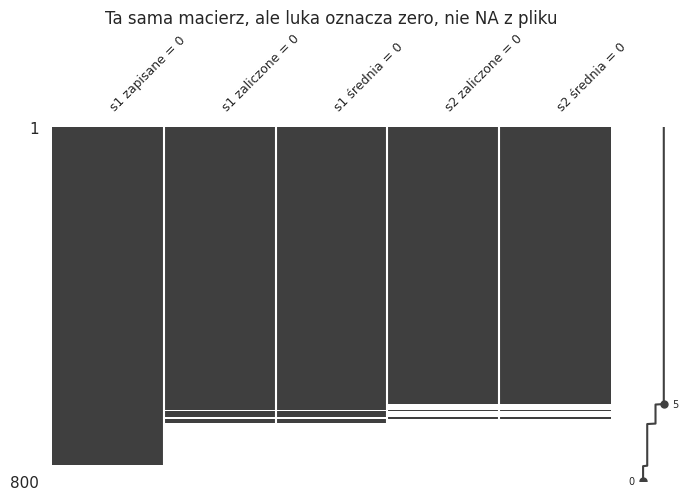

In [12]:
zero_view = pd.DataFrame({
    "s1 zapisane = 0": df[c_enr].where(~enr_zero),
    "s1 zaliczone = 0": df[c_ap1].where(~ap1_zero),
    "s1 średnia = 0": df[c_g1].where(~g1_zero),
    "s2 zaliczone = 0": df[c_ap2].where(~ap2_zero),
    "s2 średnia = 0": df[c_g2].where(~g2_zero),
})
msno.matrix(zero_view, figsize=(8, 4.6), fontsize=9, sort="descending", sparkline=True)
plt.title("Ta sama macierz, ale luka oznacza zero, nie NA z pliku")
plt.tight_layout()
plt.show()


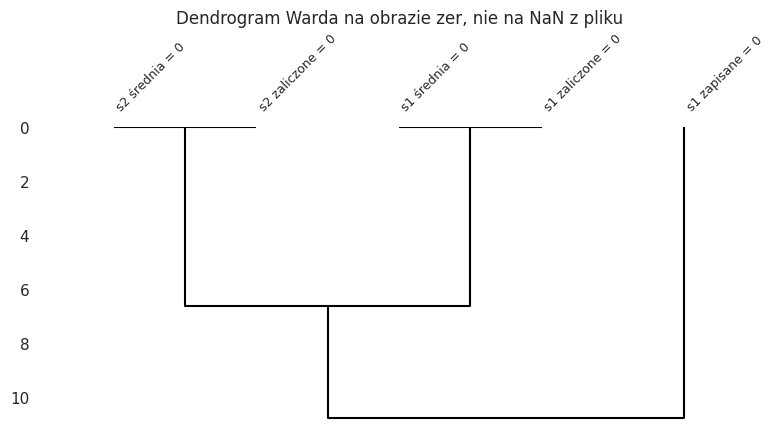

In [13]:
msno.dendrogram(zero_view, figsize=(8, 4.6), fontsize=9)
plt.title("Dendrogram Warda na obrazie zer, nie na NaN z pliku")
plt.tight_layout()
plt.show()


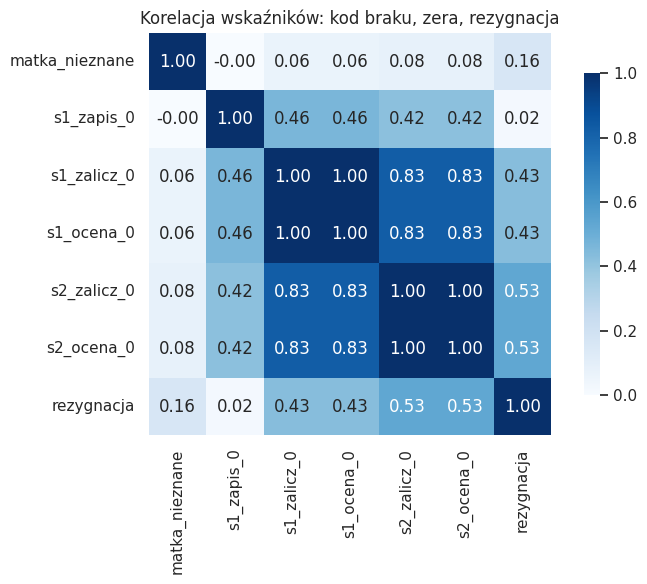

,matka_nieznane,s1_zapis_0,s1_zalicz_0,s1_ocena_0,s2_zalicz_0,s2_ocena_0,rezygnacja
matka_nieznane,1.000,-0.000,0.060,0.060,0.080,0.080,0.160
s1_zapis_0,-0.000,1.000,0.460,0.460,0.420,0.420,0.020
s1_zalicz_0,0.060,0.460,1.000,1.000,0.830,0.830,0.430
s1_ocena_0,0.060,0.460,1.000,1.000,0.830,0.830,0.430
s2_zalicz_0,0.080,0.420,0.830,0.830,1.000,1.000,0.530
s2_ocena_0,0.080,0.420,0.830,0.830,1.000,1.000,0.530
rezygnacja,0.160,0.020,0.430,0.430,0.530,0.530,1.000


In [14]:
indicators = pd.DataFrame({
    "matka_nieznane": unknown.astype(int),
    "s1_zapis_0": enr_zero.astype(int),
    "s1_zalicz_0": ap1_zero.astype(int),
    "s1_ocena_0": g1_zero.astype(int),
    "s2_zalicz_0": ap2_zero.astype(int),
    "s2_ocena_0": g2_zero.astype(int),
    "rezygnacja": dropout.astype(int),
})
corr = indicators.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Korelacja wskaźników: kod braku, zera, rezygnacja")
plt.tight_layout()
plt.show()
corr.round(2)


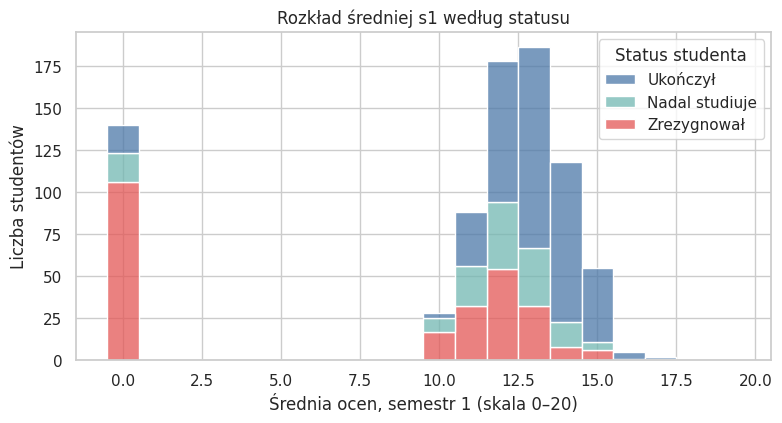

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.4))
sns.histplot(
    data=df,
    x=c_g1,
    hue=c_status,
    hue_order=STATUS_ORDER,
    bins=np.arange(-0.5, 20.5, 1),
    multiple="stack",
    palette=STATUS_COLORS,
    ax=ax,
)
ax.set_xlabel("Średnia ocen, semestr 1 (skala 0–20)")
ax.set_ylabel("Liczba studentów")
ax.set_title("Rozkład średniej s1 według statusu")
plt.tight_layout()
plt.show()


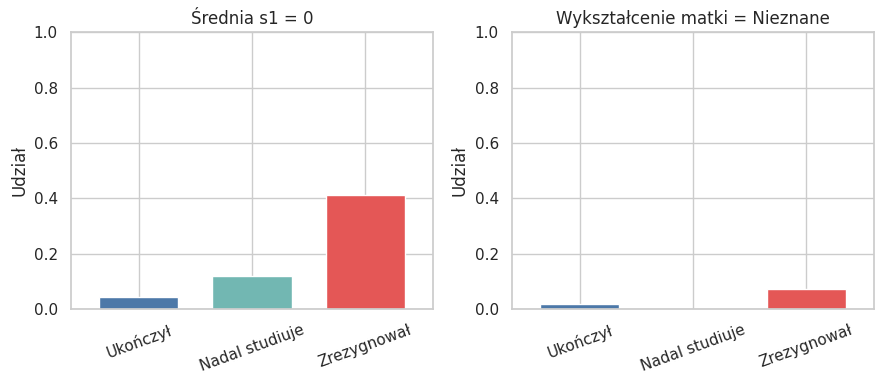

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
rate_zero.plot(kind="bar", ax=axes[0], color=[STATUS_COLORS[s] for s in STATUS_ORDER], width=0.7)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Udział")
axes[0].set_xlabel("")
axes[0].set_title("Średnia s1 = 0")
axes[0].tick_params(axis="x", rotation=20)
rate_unknown.plot(kind="bar", ax=axes[1], color=[STATUS_COLORS[s] for s in STATUS_ORDER], width=0.7)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Udział")
axes[1].set_xlabel("")
axes[1].set_title("Wykształcenie matki = Nieznane")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


Zero oceny i zero zaliczeń zgadzają się w 800/800 wierszach, w obu semestrach. Tam, gdzie zapisane przedmioty w semestrze 1 są zerem, zaliczone i średnia też są zerem. Nie przekodowuję zera na `NA` i nie imputuję go.

Na dendrogramie z zajęć połączenie nisko, blisko zera, znaczy, że kolumny mają lukę w tych samych wierszach. Tu zaliczone i średnia z tego samego semestru schodzą się przy ziemi, bo jedna wartość w pełni przewiduje drugą. Korelacja 1,00 między nimi to zgodność reguły, nie odkrycie zależności.

Słupek przy zerze na histogramie to masa osób bez zaliczeń, nie ogon rozkładu ocen pozytywnych. W tym słupku przeważają rezygnacje: zero średniej s1 ma 41,2% rezygnacji, 11,8% nadal studiujących i 4,3% osób, które studia ukończyły. Wycięcie tych wierszy ścięłoby właśnie rezygnacje.

Rezygnacja koreluje z zerami ocen wyraźniej niż z kodem `Nieznane`. To dwa różne problemy. Nie wrzucam ich do jednej imputacji.

Oba semestry na zero: 130 osób. Tylko pierwszy: 10. Tylko drugi: 34. Semestr 2 jest szerszy, bo część osób ma ocenę w pierwszym semestrze i zero w drugim, albo odwrotnie.


## 6. Reguły i brudne dane

Reguły, które da się sprawdzić na tym pliku. Twarde naruszenie to sprzeczność wewnątrz wiersza albo wartość poza skalą z opisu. Niespójność etykiet sprawdzam osobno, bez zgadywania poprawki.


In [17]:
name_evening = df[c_prog].astype(str).str.contains("wieczor", case=False)
mode_evening = df[c_mode].eq("Wieczorowe")
over23 = df[c_rec].eq("Kandydat powyżej 23 lat")

rules = pd.DataFrame([
    ("zaliczone s1 > zapisane s1", int((df[c_ap1] > df[c_enr]).sum()), "twarde naruszenie"),
    ("ocena s1 = 0, a zaliczone s1 > 0", int((g1_zero & ~ap1_zero).sum()), "twarde naruszenie"),
    ("ocena s1 > 0, a zaliczone s1 = 0", int((~g1_zero & ap1_zero).sum()), "twarde naruszenie"),
    ("ocena s2 = 0, a zaliczone s2 > 0", int((g2_zero & ~ap2_zero).sum()), "twarde naruszenie"),
    ("ocena s2 > 0, a zaliczone s2 = 0", int((~g2_zero & ap2_zero).sum()), "twarde naruszenie"),
    ("zapisane s1 = 0, a ocena s1 > 0", int((enr_zero & ~g1_zero).sum()), "twarde naruszenie"),
    ("średnia s1 poza 0–20", int(((df[c_g1] < 0) | (df[c_g1] > 20)).sum()), "poza skalą z opisu"),
    ("średnia s2 poza 0–20", int(((df[c_g2] < 0) | (df[c_g2] > 20)).sum()), "poza skalą z opisu"),
    ("wynik poprzedni poza 0–200", int(((df[c_prev] < 0) | (df[c_prev] > 200)).sum()), "poza skalą źródłową"),
    ("wynik przyjęcia poza 0–200", int(((df[c_adm] < 0) | (df[c_adm] > 200)).sum()), "poza skalą źródłową"),
    ("wiek poza 17–70", int(((df[c_age] < 17) | (df[c_age] > 70)).sum()), "poza zakresem sensownym"),
    ("bezrobocie poza 0–100", int(((df[c_unemp] < 0) | (df[c_unemp] > 100)).sum()), "poza zakresem sensownym"),
    ("preferencja poza 1–9", int(((df[c_pref] < 1) | (df[c_pref] > 9)).sum()), "poza zakresem w danych"),
    ("nazwa kierunku wieczorowa, tryb dzienny", int((name_evening & ~mode_evening).sum()), "niespójność etykiet"),
    ("tryb wieczorowy, nazwa bez wieczorowe", int((mode_evening & ~name_evening).sum()), "niespójność etykiet"),
    ("ścieżka powyżej 23 lat, wiek < 23", int((over23 & (df[c_age] < 23)).sum()), "niespójność rekrutacji"),
    ("duplikat całego wiersza", int(df.duplicated().sum()), "brudne dane"),
], columns=["regula", "naruszenia", "typ"])
rules


,regula,naruszenia,typ
0,zaliczone s1 > zapisane s1,0,twarde naruszenie
1,"ocena s1 = 0, a zaliczone s1 > 0",0,twarde naruszenie
2,"ocena s1 > 0, a zaliczone s1 = 0",0,twarde naruszenie
3,"ocena s2 = 0, a zaliczone s2 > 0",0,twarde naruszenie
4,"ocena s2 > 0, a zaliczone s2 = 0",0,twarde naruszenie
5,"zapisane s1 = 0, a ocena s1 > 0",0,twarde naruszenie
6,średnia s1 poza 0–20,0,poza skalą z opisu
7,średnia s2 poza 0–20,0,poza skalą z opisu
8,wynik poprzedni poza 0–200,0,poza skalą źródłową
9,wynik przyjęcia poza 0–200,0,poza skalą źródłową


Zaliczone s2 > zapisane s1: 47 (nie traktuję jako błędu, brak liczby zapisanych w s2)
Preferencja: min 1, max 9, zer: 0
Stopa bezrobocia, distinct: 10. To kontekst powtórzony przy wielu studentach, nie pomiar indywidualny.
Ścieżka powyżej 23 lat: 149 osób, wiek min 24.
Wiek 24+ na innej ścieżce: 78.


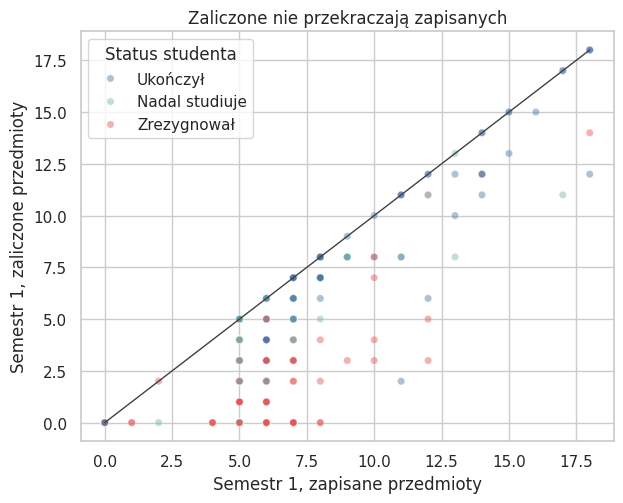

In [18]:
print("Zaliczone s2 > zapisane s1:", int((df[c_ap2] > df[c_enr]).sum()), "(nie traktuję jako błędu, brak liczby zapisanych w s2)")
print(f"Preferencja: min {int(df[c_pref].min())}, max {int(df[c_pref].max())}, zer: {int(df[c_pref].eq(0).sum())}")
print(f"Stopa bezrobocia, distinct: {df[c_unemp].nunique()}. To kontekst powtórzony przy wielu studentach, nie pomiar indywidualny.")
print(f"Ścieżka powyżej 23 lat: {int(over23.sum())} osób, wiek min {df.loc[over23, c_age].min():.0f}.")
print(f"Wiek 24+ na innej ścieżce: {int(((df[c_age] >= 24) & ~over23).sum())}.")

fig, ax = plt.subplots(figsize=(6.4, 5.2))
sns.scatterplot(
    data=df, x=c_enr, y=c_ap1, hue=c_status, hue_order=STATUS_ORDER,
    palette=STATUS_COLORS, alpha=0.45, s=28, ax=ax,
)
limit = max(df[c_enr].max(), df[c_ap1].max())
ax.plot([0, limit], [0, limit], color="0.25", lw=1)
ax.set_xlabel("Semestr 1, zapisane przedmioty")
ax.set_ylabel("Semestr 1, zaliczone przedmioty")
ax.set_title("Zaliczone nie przekraczają zapisanych")
plt.tight_layout()
plt.show()


In [19]:
mom_counts = df[c_mom].value_counts()
print(f"Poziomy wykształcenia matki o liczebności 1–2: {int((mom_counts <= 2).sum())}")
mom_counts.to_frame("n")


Poziomy wykształcenia matki o liczebności 1–2: 7


,n
Wykształcenie matki,
Wykształcenie średnie (12 lat nauki),190
Wykształcenie podstawowe – I etap,185
Wykształcenie podstawowe – III etap,183
Wykształcenie podstawowe – II etap,108
Wykształcenie wyższe – dyplom ukończenia studiów,66
Nieznane,26
Wykształcenie wyższe – licencjat,17
Inna ścieżka – 11. klasa,7
Wykształcenie wyższe – magister,6


Twardych naruszeń nie ma. Nie ma czego naprawiać funkcją w stylu `correct_sepal_width` z zajęć.

47 wierszy ma więcej zaliczonych przedmiotów w semestrze 2 niż zapisanych w semestrze 1. To nie jest błąd: w pliku nie ma liczby przedmiotów zapisanych w semestrze 2. Ekstrakt jest tu niesymetryczny. Punkty na wykresie leżą na linii równości albo pod nią. Lewy dolny róg to osoby z zerem zapisanych i zerem zaliczonych, nie chmura błędów ponad przekątną.

Opis arkusza mówi, że ranga preferencji jest 0–9 i że 0 to pierwszy wybór. W danych zera nie ma, minimum i moda są przy 1. Albo próba nie trafiła na 0, albo przy tłumaczeniu skala się przesunęła. Nie zgaduję przesunięcia. Zostawiam liczby jak w pliku, żeby 1 nie było czytane automatycznie jako drugi wybór.

Stopa bezrobocia ma 10 distinct wartości. Skrajne wartości nie są literówkami pojedynczych wierszy.

Ścieżka „kandydat powyżej 23 lat” jest spójna z wiekiem, ale nie jest jedyną drogą dla starszych kandydatów. 78 osób w wieku 24+ jest na innej ścieżce. To nie jest błąd.

Rzadkie poziomy wykształcenia matki (liczebność 1–2) zostawiam. To kategorie ze słownika UCI, nie literówki. Przy ewentualnym modelu da się je zwinąć, ale nie na etapie diagnostyki.


## 7. Obserwacje odstające

Z rozdziału o zasadach wizualizacji: odstających zwykle się nie wycina. Jeśli się wycina, decyzja ma być napisana wprost.

Dwie miary z zajęć: płot IQR i `|z| > 3`. Przy ocenach IQR jest złym nożem, bo zero jest masą, nie pojedynczym punktem.


In [20]:
numeric_cols = [
    (c_age, "wiek"),
    (c_prev, "wynik poprzedni"),
    (c_adm, "wynik przyjęcia"),
    (c_g1, "s1 średnia"),
    (c_g2, "s2 średnia"),
    (c_enr, "s1 zapisane"),
    (c_ap1, "s1 zaliczone"),
    (c_ap2, "s2 zaliczone"),
    (c_pref, "preferencja"),
    (c_unemp, "bezrobocie"),
]
outlier_rows = []
for col, label in numeric_cols:
    low, high = iqr_bounds(df[col])
    z = pd.Series(stats.zscore(df[col], ddof=1), index=df.index)
    outlier_rows.append({
        "zmienna": label,
        "iqr_dol": round(float(low), 2),
        "iqr_gora": round(float(high), 2),
        "n_iqr": int(((df[col] < low) | (df[col] > high)).sum()),
        "n_|z|>3": int((z.abs() > 3).sum()),
        "min": df[col].min(),
        "max": df[col].max(),
    })
outlier_df = pd.DataFrame(outlier_rows)
outlier_df


,zmienna,iqr_dol,iqr_gora,n_iqr,n_|z|>3,min,max
0,wiek,7.500,35.500,82,16,18.000,59.000
1,wynik poprzedni,99.380,164.380,14,3,99.000,190.000
2,wynik przyjęcia,93.610,158.310,33,6,95.000,190.000
3,s1 średnia,7.500,16.830,141,0,0.000,17.333
4,s2 średnia,7.030,17.110,164,0,0.000,17.000
5,s1 zapisane,2.000,10.000,72,18,0.000,18.000
6,s1 zaliczone,-1.500,10.500,27,11,0.000,18.000
7,s2 zaliczone,-4.000,12.000,9,5,0.000,17.000
8,preferencja,-0.500,3.500,113,27,1.000,9.000
9,bezrobocie,2.650,20.650,0,0,7.600,16.200


Flagi IQR na średniej s1: 141, z tego zero: 140.
IQR tylko dla średniej s1 > 0: płot 9.07–16.22, flag 2.


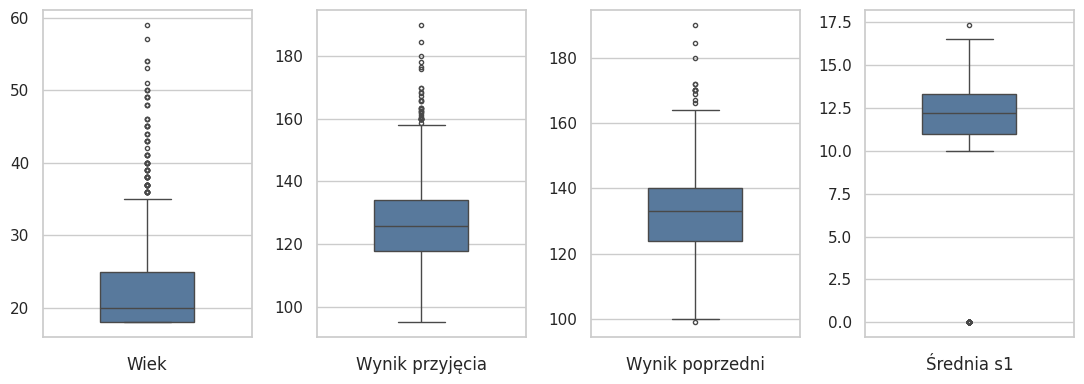

In [21]:
g1_low, g1_high = iqr_bounds(df[c_g1])
g1_iqr = (df[c_g1] < g1_low) | (df[c_g1] > g1_high)
pos_low, pos_high = iqr_bounds(df.loc[~g1_zero, c_g1])
pos_flag = int(((df.loc[~g1_zero, c_g1] < pos_low) | (df.loc[~g1_zero, c_g1] > pos_high)).sum())
print(f"Flagi IQR na średniej s1: {int(g1_iqr.sum())}, z tego zero: {int((g1_iqr & g1_zero).sum())}.")
print(f"IQR tylko dla średniej s1 > 0: płot {pos_low:.2f}–{pos_high:.2f}, flag {pos_flag}.")

fig, axes = plt.subplots(1, 4, figsize=(11, 4))
for ax, col, label in zip(axes, [c_age, c_adm, c_prev, c_g1], ["Wiek", "Wynik przyjęcia", "Wynik poprzedni", "Średnia s1"]):
    sns.boxplot(y=df[col], ax=ax, color="#4c78a8", width=0.45, fliersize=3)
    ax.set_xlabel(label)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()


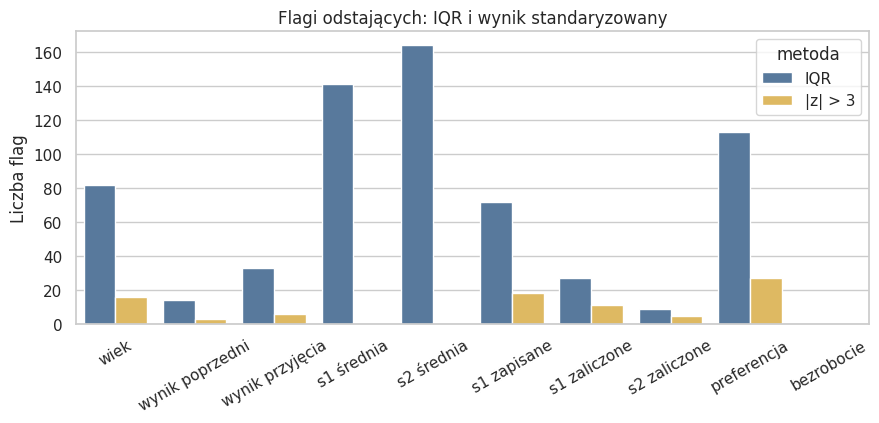

In [22]:
plot_out = outlier_df.melt(id_vars="zmienna", value_vars=["n_iqr", "n_|z|>3"], var_name="metoda", value_name="n")
plot_out["metoda"] = plot_out["metoda"].map({"n_iqr": "IQR", "n_|z|>3": "|z| > 3"})
fig, ax = plt.subplots(figsize=(9, 4.4))
sns.barplot(data=plot_out, x="zmienna", y="n", hue="metoda", ax=ax, palette=["#4c78a8", "#f2c14e"])
ax.set_xlabel("")
ax.set_ylabel("Liczba flag")
ax.set_title("Flagi odstających: IQR i wynik standaryzowany")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


Z flag IQR na średniej s1 prawie wszystkie to zera. Reszta to pojedyncze wysokie oceny, nadal wewnątrz skali 0–20. Gdy liczę płot tylko dla średniej powyżej zera, flag zostaje kilka, nie sto kilkadziesiąt. Zero robi z oceny sztuczny ogon.

Wieku powyżej górnego płotu IQR nie usuwam. Maksimum 59 mieści się w ścieżce kandydatów starszych. `|z| > 3` jest ostrzejsze i też nie wskazuje literówki.

Preferencja powyżej płotu IQR to dalsze wybory niż 1–2. Ranga nie jest błędem tylko dlatego, że wychodzi poza środek rozkładu.

Tam, gdzie słupek IQR jest dużo wyższy niż `|z| > 3`, płot łapie masę albo skośny rozkład, nie pojedyncze błędy zapisu.

Decyzja: nic nie wycinam. Przy późniejszych wykresach ocen mogę pokazać panel bez zer, ale obok, nie zamiast.


## 8. Co zrobić z brakiem

Z trzech kroków z zajęć zostaje decyzja: usunąć wiersze, usuwać parami, albo imputować. Sprawdzam, co każda z tych dróg zrobiłaby z udziałem rezygnacji. Imputacji nie zapisuję.


In [23]:
dropped = df.loc[known]
rate_all = dropout.mean()
rate_dropped = dropped[c_status].eq("Zrezygnował").mean()
print(f"Usunięcie 26 wierszy z Nieznane: rezygnacje {rate_all:.1%} -> {rate_dropped:.1%}.")
print("To jest obciążenie z rozdziału o brakach. Domyślne dropna przy wykształceniu matki wycina nieproporcjonalnie rezygnacje.")
print("Usuwanie parami zostawiam jako zasadę na później: korelacja dwóch kolumn bez wykształcenia matki i tak używa wszystkich 800 wierszy.")

mom_before = df[c_mom].value_counts()
imputed = pd.Series(
    SimpleImputer(strategy="most_frequent").fit_transform(work[[c_mom]]).ravel(),
    index=work.index,
)
mom_after = imputed.value_counts()
mode_label = mom_before.index[0]
print(f"SimpleImputer(strategy='most_frequent') wstawiłby: {mode_label}.")
print(f"Liczebność tej kategorii: {int(mom_before.iloc[0])} przed, {int(mom_after.loc[mode_label])} po. Nieznane znika.")

compare = pd.DataFrame({"przed": mom_before, "po imputacji modą": mom_after}).fillna(0).astype(int)
compare = compare.sort_values("przed", ascending=False)
compare


Usunięcie 26 wierszy z Nieznane: rezygnacje 32.1% -> 30.7%.
To jest obciążenie z rozdziału o brakach. Domyślne dropna przy wykształceniu matki wycina nieproporcjonalnie rezygnacje.
Usuwanie parami zostawiam jako zasadę na później: korelacja dwóch kolumn bez wykształcenia matki i tak używa wszystkich 800 wierszy.
SimpleImputer(strategy='most_frequent') wstawiłby: Wykształcenie średnie (12 lat nauki).
Liczebność tej kategorii: 190 przed, 216 po. Nieznane znika.


,przed,po imputacji modą
Wykształcenie średnie (12 lat nauki),190,216
Wykształcenie podstawowe – I etap,185,185
Wykształcenie podstawowe – III etap,183,183
Wykształcenie podstawowe – II etap,108,108
Wykształcenie wyższe – dyplom ukończenia studiów,66,66
Nieznane,26,0
Wykształcenie wyższe – licencjat,17,17
Inna ścieżka – 11. klasa,7,7
Wykształcenie wyższe – magister,6,6
Wykształcenie wyższe – doktor,4,4


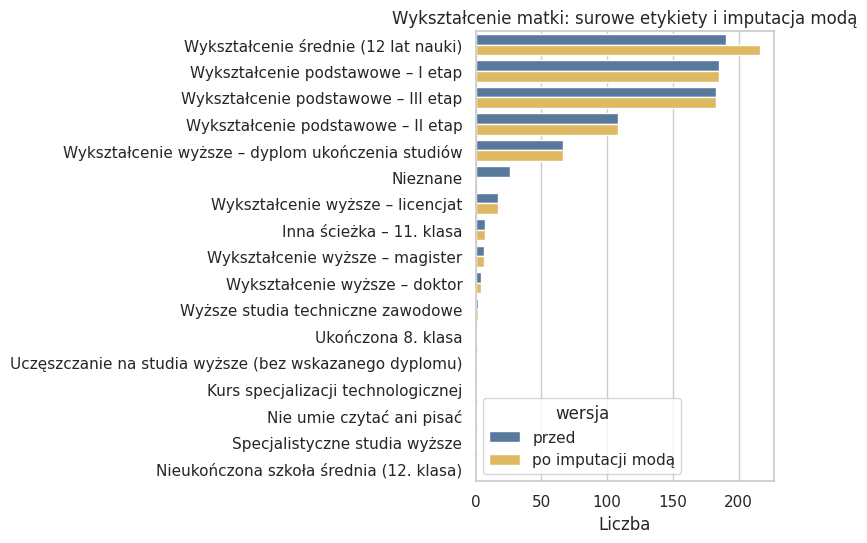

In [24]:
plot_cmp = compare.reset_index().melt(id_vars=compare.index.name or "index", var_name="wersja", value_name="n")
id_col = plot_cmp.columns[0]
fig, ax = plt.subplots(figsize=(8, 5.6))
sns.barplot(data=plot_cmp, y=id_col, x="n", hue="wersja", ax=ax, palette=["#4c78a8", "#f2c14e"])
ax.set_xlabel("Liczba")
ax.set_ylabel("")
ax.set_title("Wykształcenie matki: surowe etykiety i imputacja modą")
plt.tight_layout()
plt.show()


Imputacja modą jest tu imputacją stałą z zajęć. Skala jest nominalna, więc średnia nie ma sensu, mediana też nie. Różnica na wykresie dotyczy tylko `Nieznane` i kategorii modalnej, czyli wykształcenia średniego (12 lat nauki): 190 przed, 216 po. Reszta słupków stoi w miejscu.

Tej poprawki nie przyjmuję. Dokleja rezygnacje do najczęstszego wykształcenia i chowa związek braku ze statusem.

KNN, hot deck i `IterativeImputer` też odpadają. Nie ma drugiej luki numerycznej do uzupełnienia, a zero oceny nie jest wartością do przewidzenia z sąsiadów. Wielokrotnej imputacji nie uruchamiam z tego samego powodu. Przy jednym kodzie kategorycznym i wyraźnym związku ze statusem więcej da osobny poziom niż MICE.


## 9. Co zostaje do dalszej analizy

Dalsze wykresy i tabele opisowe dopisujemy w tym notatniku, na surowych kolumnach. `Nieznane` zostaje etykietą. Zera zostają zerami.

Jedyna rzecz do ręcznego obejrzenia, nie do usunięcia: osoba ukończyła studia, a średnia z semestru 1 jest zerem. Może być przeniesienie zaliczeń albo ocena z późniejszego semestru, którego w tym ekstrakcie nie ma.


In [25]:
flagi = pd.DataFrame({
    "status": df[c_status],
    "brak_wyksztalcenie_matki": unknown.astype(int),
    "blok_zer_s1": (enr_zero & ap1_zero & g1_zero).astype(int),
    "ocena_s1_zero": g1_zero.astype(int),
    "ocena_s2_zero": g2_zero.astype(int),
    "ukonczyl_mimo_zera_s1": (df[c_status].eq("Ukończył") & g1_zero).astype(int),
})
print(flagi.sum().to_string())
print()
cols = [c_status, c_age, c_prog, c_enr, c_ap1, c_g1, c_ap2, c_g2]
df.loc[flagi["ukonczyl_mimo_zera_s1"].eq(1), cols]


status                      ZrezygnowałUkończyłNadal studiujeUkończyłNadal...
brak_wyksztalcenie_matki                                                   26
blok_zer_s1                                                                35
ocena_s1_zero                                                             140
ocena_s2_zero                                                             164
ukonczyl_mimo_zera_s1                                                      17



,Status studenta,Wiek w chwili rozpoczęcia studiów,Kierunek studiów,Semestr 1 – liczba zapisanych przedmiotów,Semestr 1 – liczba zaliczonych przedmiotów,Semestr 1 – średnia ocen,Semestr 2 – liczba zaliczonych przedmiotów,Semestr 2 – średnia ocen
35,Ukończył,18,Projektowanie animacji i multimediów,0,0,0.000,0,0.000
80,Ukończył,20,Projektowanie animacji i multimediów,0,0,0.000,0,0.000
81,Ukończył,21,Projektowanie animacji i multimediów,0,0,0.000,0,0.000
83,Ukończył,19,Projektowanie animacji i multimediów,0,0,0.000,0,0.000
149,Ukończył,18,Projektowanie animacji i multimediów,0,0,0.000,0,0.000
182,Ukończył,19,Projektowanie animacji i multimediów,0,0,0.000,0,0.000
252,Ukończył,18,Projektowanie animacji i multimediów,0,0,0.000,0,0.000
260,Ukończył,20,Projektowanie animacji i multimediów,0,0,0.000,0,0.000
345,Ukończył,18,Projektowanie animacji i multimediów,0,0,0.000,0,0.000
382,Ukończył,19,Projektowanie animacji i multimediów,0,0,0.000,0,0.000


## 10. Krótko

Braków w sensie `NaN` nie ma. Jedyny kod braku to `Nieznane` przy wykształceniu matki, 26 wierszy. Jest związany ze statusem, więc nie traktuję go jak MCAR i nie usuwam tych wierszy.

Zera ocen są kompletne względem zaliczeń i leżą na skali z opisu. To jakość wyniku, nie luka do imputacji.

Reguły logiczne, które da się sprawdzić, trzymają się. Niezgodność jest w opisie preferencji (0 w dokumentacji, 1 w danych), nie w komórkach.

Odstających nie usuwam. IQR na ocenach głównie odtwarza zero.

Gdy będę liczył statystyki wykształcenia matki, podam liczebność `Nieznane` obok, a nie w mianowniku ukrytym przez `dropna`.
